# 10 — Perfil del hospital: quién llega, a quién se atiende y por qué se remite

## Qué contesta este cuaderno

El conteo de triages mide la puerta del SES Hospital Universitario de Caldas: cuántas personas piden ser clasificadas. Lo que ocurre después de la puerta, es decir, a quién se atiende aquí, en qué servicio, con qué diagnóstico y a quién se remite, determina qué factores externos pueden mover ese conteo y en qué subgrupo. Un frío que enferma a los mayores solo aparecerá en el triage si los mayores llegan a esta puerta y se quedan en ella; una fiesta que produce trauma solo aparecerá si el trauma se atiende aquí. Este cuaderno describe al hospital con agregados del propio sistema para fijar esas condiciones antes de modelar nada.

## Contexto institucional

Según la información que dio la dirección del hospital, y que no se mide en este cuaderno, el SES recibe a cualquier persona que llegue con una urgencia, por razones legales y morales, pero no siempre puede resolverla. Donde no hay especialista se estabiliza y se remite: los niños, al Hospital Infantil, que no tiene urgencias de puerta, y lo cardiovascular, a una clínica especializada. Los accidentes de tránsito llegan al hospital más cercano, en ambulancia. El criterio general es que remitir es mejor que tratar con limitaciones. Las secciones 1 y 5 contrastan esa descripción con los números.

## Cómo se protege a las personas

- Solo salen conteos agregados por mes, semana o año y por categorías de catálogo (área de servicio, capítulo CIE-10, motivo de remisión). Ninguna fila corresponde a un paciente: los ingresos, los folios y los diagnósticos se unen dentro de la base y solo sale el conteo.
- En origen se ocultó toda casilla con menos de 5 casos. Por eso algunas sumas son algo menores que el total real, y los porcentajes de las casillas ocultas no se pueden recuperar.
- No se consulta texto libre: ni el motivo de consulta ni el motivo escrito de la remisión.
- Este cuaderno añade una segunda barrera. Ninguna tabla muestra una casilla con menos de 20 casos: las categorías pequeñas se suman en «otras» y las casillas que aun así quedan por debajo de 20 se muestran como «<20». Los gráficos de calor omiten el número de las casillas con menos de 20 casos. Los códigos de diagnóstico de tres caracteres, que por mes pueden tener pocos casos, solo se usan sumados a todo el periodo. La tabla diaria por capítulo no se utiliza.

## De dónde salen los datos

| Tabla | Qué es |
|---|---|
| `perfil_ingreso_banda`, `perfil_ingreso_nivel` | Triages por mes que pasan o no a ingreso, por banda de edad y por nivel de triage |
| `perfil_area_mensual` | Ingresos por mes y área de servicio (catálogo `AREA_SERVICIO`) |
| `perfil_causa_mensual` | Ingresos por mes y causa de ingreso (un código; la base no trae catálogo) |
| `perfil_dx_semanal`, `perfil_dx_edad_anual`, `perfil_dx_codigo_mensual` | Diagnóstico principal CIE-10 del ingreso: capítulo por semana, capítulo por edad y año, y código de tres caracteres por mes |
| `perfil_remisiones_motivo`, `perfil_remisiones_servicio` | Remisiones por motivo (catálogo de 6 valores) y por servicio que remite |

Todas salen del módulo `extraccion`, que no se ejecuta aquí: el cuaderno solo lee los archivos ya guardados en `salidas/`. Los diagnósticos se agrupan en los 22 capítulos de la CIE-10 (`extraccion/cie10.py`). El periodo va de enero de 2020 a septiembre de 2026; septiembre de 2026 está incompleto.


In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
CATEG = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO]
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
SECUENCIAL = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#86b6ef", "#2a78d6", "#104281"])
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
S = RAIZ / "salidas"
leer = lambda n: pd.read_parquet(S / f"{n}.parquet")
ib, iv = leer("perfil_ingreso_banda"), leer("perfil_ingreso_nivel")
area, causa = leer("perfil_area_mensual"), leer("perfil_causa_mensual")
dxs, dxe, dxc = leer("perfil_dx_semanal"), leer("perfil_dx_edad_anual"), leer("perfil_dx_codigo_mensual")
rm, rs = leer("perfil_remisiones_motivo"), leer("perfil_remisiones_servicio")
for t in (ib, iv, area, causa, dxc, rm):
    t["mes"] = pd.to_datetime(t["mes"]); t["anio"] = t["mes"].dt.year
dxs["semana"] = pd.to_datetime(dxs["semana"])
for t, c in [(area, "area"), (rs, "servicio"), (rm, "motivo"), (iv, "nivel"), (ib, "banda"), (causa, "causa"), (dxs, "capitulo"), (dxe, "capitulo"), (dxe, "banda"), (dxc, "capitulo")]:
    t[c] = t[c].str.strip()   # las columnas de catálogo vienen rellenas con espacios
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
UMBRAL = 20   # ninguna casilla por debajo de este número se muestra en una tabla

def es(x, d=1):
    """Número con coma decimal y punto de millar."""
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def ocultar(tabla, umbral=UMBRAL):
    """Sustituye por «<umbral» toda casilla de conteo menor que el umbral (o suprimida en origen) antes de mostrarla."""
    out = tabla.astype(object).copy()
    for c in out.columns:
        for i in out.index:
            v = tabla.loc[i, c]
            out.loc[i, c] = f"<{umbral}" if (pd.isna(v) or v < umbral) else es(v, 0)
    return out

fuentes = [("ingreso×edad", ib), ("ingreso×nivel", iv), ("área", area), ("causa", causa), ("dx semanal", dxs),
           ("dx×edad", dxe), ("remisión×motivo", rm), ("remisión×servicio", rs)]
print("casillas ocultas en origen por tabla (%):", {n: round(100 * t["suprimido"].mean(), 1) for n, t in fuentes})
print("casilla más pequeña visible en origen:", {n: int(t.loc[~t.suprimido, "n"].min()) for n, t in fuentes})
print("periodo:", ib.mes.min().date(), "a", ib.mes.max().date(), "(el último mes está incompleto)")

casillas ocultas en origen por tabla (%): {'ingreso×edad': 6.7, 'ingreso×nivel': 30.7, 'área': 36.1, 'causa': 25.2, 'dx semanal': 20.6, 'dx×edad': 22.4, 'remisión×motivo': 33.3, 'remisión×servicio': 6.8}
casilla más pequeña visible en origen: {'ingreso×edad': 5, 'ingreso×nivel': 5, 'área': 5, 'causa': 5, 'dx semanal': 5, 'dx×edad': 5, 'remisión×motivo': 5, 'remisión×servicio': 5}
periodo: 2020-01-01 a 2026-09-01 (el último mes está incompleto)


---
# 1. De la puerta al ingreso

Un triage pasa a ingreso cuando el hospital toma al paciente. Si no pasa, se orienta a otro lugar: su EPS, la consulta externa u otra institución. Es la frontera entre «llegó» y «se atiende aquí», y su nivel y su estabilidad deciden cuánto del conteo de triage describe, en realidad, a pacientes del SES.


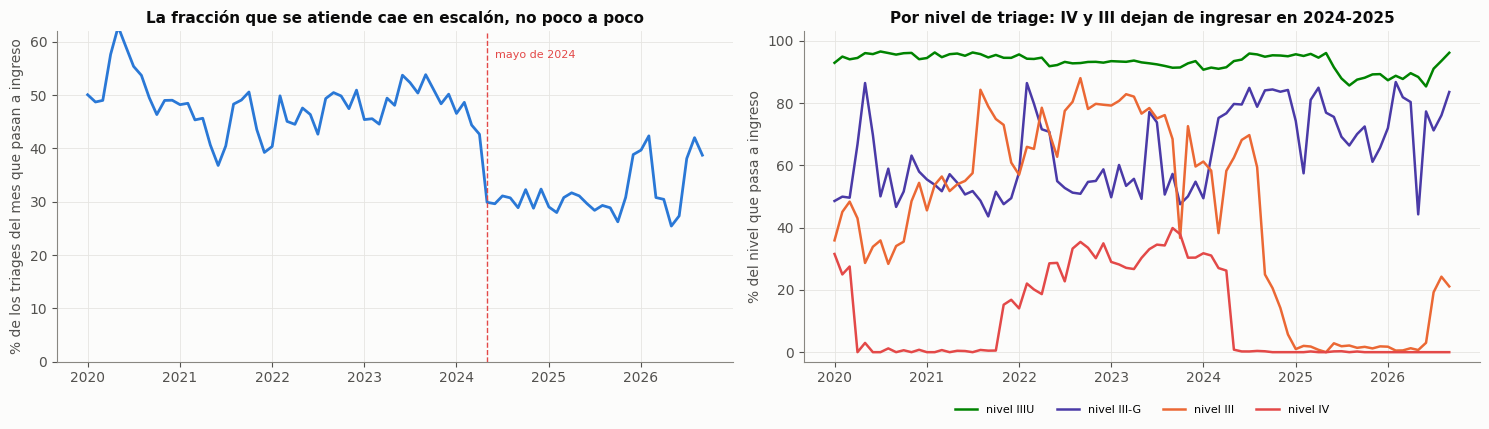

,triages,con ingreso,% con ingreso
anio,,,
2020,38.659,19.937,"51,6"
2021,54.494,24.215,"44,4"
2022,69.206,32.452,"46,9"
2023,70.215,34.743,"49,5"
2024,82.379,28.989,"35,2"
2025,72.838,21.854,"30,0"
2026,47.121,16.175,"34,3"


meses alrededor del escalón (triages del mes, % con ingreso):


mes,2024-03,2024-04,2024-05,2024-06
con_ingreso,,,,
t,6000.0,7427.0,7697.0,7298.0
p,44.4,42.7,29.9,29.6


nivel IV, % con ingreso: {'2024-03': 27.0, '2024-04': 26.2, '2024-05': 0.8, '2024-06': 0.2}
nivel III, % con ingreso: {'2024-08': 59.3, '2024-09': 24.9, '2024-10': 20.6, '2024-11': 14.2, '2024-12': 5.7, '2025-01': 1.0, '2025-02': 2.0}
nivel III, triages por mes: {'2024-12': 316, '2025-01': 706}
nivel IV, triages por mes: {'2024-03': 2516, '2024-04': 3403, '2024-05': 4014, '2024-06': 3776}
% con ingreso, dic-2025 y ene-2026: [38.8, 39.7] | triages dic-2025: 4578


In [2]:
# 1.1 Fracción mensual que pasa a ingreso, y en qué niveles
m = ib.groupby(["mes", "con_ingreso"]).n.sum().unstack(); m["t"] = m.sum(axis=1); m["p"] = 100 * m[1] / m.t
a = ib.groupby(["anio", "con_ingreso"]).n.sum().unstack()
tot = a.sum(axis=1); pct_ing = 100 * a[1] / tot
g = iv.groupby(["mes", "nivel", "con_ingreso"]).n.sum().unstack().fillna(0); g["t"] = g.sum(axis=1); g["p"] = 100 * g[1] / g.t

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
ax = axes[0]
ax.plot(m.index, m.p, color=AZUL, lw=2)
ax.axvline(pd.Timestamp("2024-05-01"), color=ROJO, lw=1, ls="--"); ax.text(pd.Timestamp("2024-06-01"), 57, "mayo de 2024", color=ROJO, fontsize=8)
ax.set_ylim(0, 62); ax.set_ylabel("% de los triages del mes que pasan a ingreso")
ax.set_title("La fracción que se atiende cae en escalón, no poco a poco")
for nv, col in [("IIIU", VERDE), ("III-G", VIOLETA), ("III", NARANJA), ("IV", ROJO)]:
    s = g.xs(nv, level="nivel")
    axes[1].plot(s.index, s.p, color=col, lw=1.8, label=f"nivel {nv}")
axes[1].set_ylim(-3, 103); axes[1].set_ylabel("% del nivel que pasa a ingreso"); axes[1].legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.1))
axes[1].set_title("Por nivel de triage: IV y III dejan de ingresar en 2024-2025")
plt.tight_layout(); plt.show()

anual = pd.DataFrame({"triages": tot, "con ingreso": a[1], "% con ingreso": pct_ing})
display(anual.style.format({"triages": lambda v: es(v, 0), "con ingreso": lambda v: es(v, 0), "% con ingreso": lambda v: es(v, 1)}))
mm = m.loc["2024-03-01":"2024-06-01", ["t", "p"]].round(1); mm.index = mm.index.strftime("%Y-%m")
print("meses alrededor del escalón (triages del mes, % con ingreso):"); display(mm.T)
print("nivel IV, % con ingreso:", {k.strftime("%Y-%m"): round(v, 1) for k, v in g.xs("IV", level="nivel").p.loc["2024-03-01":"2024-06-01"].items()})
print("nivel III, % con ingreso:", {k.strftime("%Y-%m"): round(v, 1) for k, v in g.xs("III", level="nivel").p.loc["2024-08-01":"2025-02-01"].items()})
print("nivel III, triages por mes:", {k.strftime("%Y-%m"): int(v) for k, v in g.xs("III", level="nivel").t.loc[["2024-12-01", "2025-01-01"]].items()})
print("nivel IV, triages por mes:", {k.strftime("%Y-%m"): int(v) for k, v in g.xs("IV", level="nivel").t.loc["2024-03-01":"2024-06-01"].items()})
print("% con ingreso, dic-2025 y ene-2026:", m.p.loc[["2025-12-01", "2026-01-01"]].round(1).tolist(), "| triages dic-2025:", int(m.t.loc["2025-12-01"]))

## Lectura

**El SES recibe a todos, pero se queda con una parte, y esa parte cayó en escalones y no de forma gradual.**

La fracción de triages que pasa a ingreso fue de 49,5 % en 2023 y de 30,0 % en 2025 (51,6 % en 2020, 44,4 % en 2021, 46,9 % en 2022, 35,2 % en 2024; 34,3 % en 2026 hasta septiembre). El gráfico mensual muestra que la bajada de 2024 es un escalón: de 44,4 % en marzo y 42,7 % en abril a 29,9 % en mayo, con 6.000, 7.427 y 7.697 triages en esos meses. El volumen había subido en abril de 2024, el mes del escalón de SURA que se describe en el cuaderno 18, y la fracción con ingreso bajó al mes siguiente, lo que es compatible con que lo añadido a la puerta no se ingresara.

El detalle por nivel de triage muestra dónde ocurrió. El nivel IV pasa de 26,2 % con ingreso en abril de 2024 a 0,8 % en mayo y 0,2 % en junio, mientras su volumen sube de 3.403 a 4.014 triages mensuales. El nivel III cae después, también en escalones: 59,3 % en agosto de 2024, 24,9 % en septiembre, 14,2 % en noviembre, 5,7 % en diciembre y 1,0 % en enero de 2025, mes en que sus triages pasan de 316 a 706. El nivel IIIU se mantiene entre 89,5 % y 95,2 % cada año, y el nivel V prácticamente no ingresa nunca (0,1 % como máximo en un año).

**La crisis de Nueva EPS no explica el escalón.** El escalón es de mayo de 2024; el desplome de Nueva EPS en el SES es de noviembre de 2025 (cuaderno 18). Lo que se ve después, en diciembre de 2025 y enero de 2026, es que la fracción sube a 38,8 % y 39,7 % cuando el denominador cae (4.578 triages en diciembre de 2025). Una lectura compatible con los datos es que la puerta perdió triages de baja gravedad que de todos modos no se ingresaban.


In [3]:
# 1.2 ¿Cambió la mezcla de niveles o lo que se hace dentro de cada nivel?
ga = iv.groupby(["anio", "nivel", "con_ingreso"]).n.sum().unstack().fillna(0); ga["t"] = ga.sum(axis=1)
tasa = (ga[1] / ga.t).unstack(); cuenta = ga.t.unstack()
base = cuenta.loc[[2022, 2023]].sum(); base = base / base.sum()
est = pd.Series({y: 100 * (tasa.loc[y].fillna(0) * base).sum() for y in tasa.index})
obs = 100 * ga[1].groupby(level=0).sum() / ga.t.groupby(level=0).sum()
mezcla = 100 * cuenta.div(cuenta.sum(axis=1), axis=0)
t = pd.DataFrame({"observado": obs, "con la mezcla de niveles de 2022-2023": est})
display(t.style.format(lambda v: es(v, 1)))
cl = ["III", "IV", "V", "IIIU", "III-G"]
print("% de los triages del año que cae en cada nivel:"); display(mezcla[cl].style.format(lambda v: es(v, 1)))
print("% de cada nivel que pasa a ingreso:"); display((100 * tasa[cl]).style.format(lambda v: es(v, 1)))

,observado,con la mezcla de niveles de 2022-2023
2020,"51,6","38,4"
2021,"44,5","36,3"
2022,"46,9","47,4"
2023,"49,5","49,0"
2024,"35,2","39,8"
2025,"30,0","32,8"
2026,"34,3","32,9"


% de los triages del año que cae en cada nivel:


nivel,III,IV,V,IIIU,III-G
anio,,,,,
2020,"10,1","19,3","16,1","35,0","13,5"
2021,"9,2","35,2","10,9","29,1","11,8"
2022,"4,5","45,5","12,2","24,4","10,3"
2023,"4,2","46,5","10,4","25,4","11,2"
2024,"5,1","48,4","14,1","21,2","9,3"
2025,"15,4","37,1","12,6","21,5","10,0"
2026,"25,3","27,0","9,5","20,9","12,6"


% de cada nivel que pasa a ingreso:


nivel,III,IV,V,IIIU,III-G
anio,,,,,
2020,"38,5","10,5","0,0","95,0","57,6"
2021,"69,5","4,5","0,0","95,2","51,0"
2022,"73,1","26,8","0,0","93,3","61,4"
2023,"72,1","32,0","0,0","92,6","56,6"
2024,"47,9","8,5","0,1","93,5","76,4"
2025,"1,6","0,1","0,0","91,3","71,4"
2026,"8,5","0,0","0,0","89,5","74,3"


## Lectura

**La caída no se debe a un cambio en la mezcla de niveles de triage.** Con la mezcla de niveles de 2022-2023 fija, la fracción de ingreso sería de 39,8 % en 2024, 32,8 % en 2025 y 32,9 % en 2026, frente a los 35,2 %, 30,0 % y 34,3 % observados: la caída, de 49,0 % en 2023 a 32,8 % en 2025, ocurre dentro de los niveles. Dentro del nivel III la tasa de ingreso fue de 72,1 % en 2023, 47,9 % en 2024 y 1,6 % en 2025; dentro del IV, de 32,0 % a 8,5 % y 0,1 %. El nivel III-G, que corresponde a la atención obstétrica, sube de 56,6 % en 2023 a 76,4 % en 2024. A la vez, el nivel III pasa de 4,2 % de los triages en 2023 a 15,4 % en 2025 y 25,3 % en 2026, y el IV baja de 46,5 % a 37,1 % y 27,0 %. Esto coincide con la reclasificación del nivel de triage del cuaderno 01, aunque estos agregados no permiten verificar que sea su causa.

**El nivel de triage es, en la práctica, la decisión de tomar o no, pero esa decisión cambió con los años.** Los niveles I, II y IIIU ingresan casi siempre y el V casi nunca; los niveles III y IV son donde se movió la frontera. Por eso las tasas por nivel de un periodo completo mezclan dos regímenes y no son comparables entre años.

**Límite.** Los datos no permiten distinguir si en mayo de 2024 cambió la política de ingreso, el registro del ingreso o quién llega. Tampoco dicen cuánto tiempo ni con qué desenlace se atiende a quien ingresa. El 30,7 % de las casillas mes × nivel está oculto en origen, lo que afecta sobre todo a los niveles pequeños.


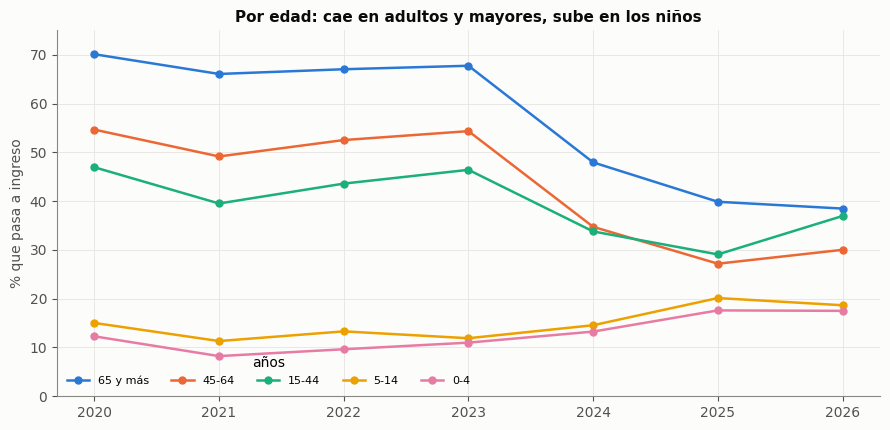

% con ingreso, periodo completo:


,% con ingreso
banda,
65-+,"55,3"
45-64,"42,6"
15-44,"39,0"
5-14,"15,4"
0-4,"13,3"


% con ingreso por año y edad:


banda,65-+,45-64,15-44,5-14,0-4
anio,,,,,
2020,"70,1","54,7","46,9","15,0","12,3"
2021,"66,1","49,2","39,5","11,3","8,2"
2022,"67,0","52,5","43,6","13,3","9,6"
2023,"67,7","54,3","46,4","11,9","11,0"
2024,"47,9","34,7","33,8","14,6","13,3"
2025,"39,9","27,2","29,1","20,1","17,6"
2026,"38,5","30,0","37,0","18,7","17,5"


menor número de triages en una casilla año × edad (denominador): 708


In [4]:
# 1.3 Por edad
por = ib.groupby(["anio", "banda", "con_ingreso"]).n.sum().unstack()
pb = (100 * por[1] / por.sum(axis=1)).unstack()
den = por.sum(axis=1).unstack()
orden = ["65-+", "45-64", "15-44", "5-14", "0-4"]
fig, ax = plt.subplots(figsize=(9, 4.4))
for i, b in enumerate(orden):
    ax.plot(pb.index, pb[b], marker="o", ms=5, color=CATEG[i], lw=1.8, label={"65-+": "65 y más"}.get(b, b))
ax.set_ylabel("% que pasa a ingreso"); ax.set_title("Por edad: cae en adultos y mayores, sube en los niños")
ax.legend(title="años", ncol=5, loc="lower left", fontsize=8); ax.set_ylim(0, 75)
plt.tight_layout(); plt.show()
gg = ib.groupby(["banda", "con_ingreso"]).n.sum().unstack()
print("% con ingreso, periodo completo:"); display((100 * gg[1] / gg.sum(axis=1)).loc[orden].to_frame("% con ingreso").style.format(lambda v: es(v, 1)))
print("% con ingreso por año y edad:"); display(pb[orden].style.format(lambda v: es(v, 1)))
print("menor número de triages en una casilla año × edad (denominador):", int(den[orden].min().min()))

## Lectura

**Por edad, el ingreso cae en los adultos y los mayores y sube en los niños.** En el periodo completo, la fracción con ingreso es de 55,3 % en los mayores de 65 años, 42,6 % de 45 a 64, 39,0 % de 15 a 44, 15,4 % de 5 a 14 y 13,3 % de 0 a 4. Eso coincide con la descripción institucional: los niños se estabilizan y se remiten, y los mayores se quedan. El promedio de siete años oculta, sin embargo, un cambio: entre 2023 y 2025 la fracción de los mayores de 65 pasó de 67,7 % a 39,9 %, la de 45 a 64 de 54,3 % a 27,2 % y la de 15 a 44 de 46,4 % a 29,1 %, mientras la de 0 a 4 años subió de 11,0 % a 17,6 % y la de 5 a 14 de 11,9 % a 20,1 %.

**Límite.** Cada casilla año × edad tiene al menos 708 triages, de modo que las diferencias entre bandas no son ruido de conteos pequeños. La mezcla de niveles de triage dentro de cada banda no se separa aquí.


---
# 2. Dónde se atiende y por qué causa de ingreso

Se describe el área de servicio del ingreso (catálogo del hospital) y la causa de ingreso. La causa viene como un código sin catálogo en la base, y no existe un diccionario de esos códigos. Solo se rotulan tres, con evidencia indirecta obtenida al cruzar cada código con el asegurador del triage: el 6 (74 % de los casos con SOAT) como accidente de tránsito, el 10 (74 % con ARL) como accidente laboral y el 3 como enfermedad general. Los demás se mantienen como «código N».


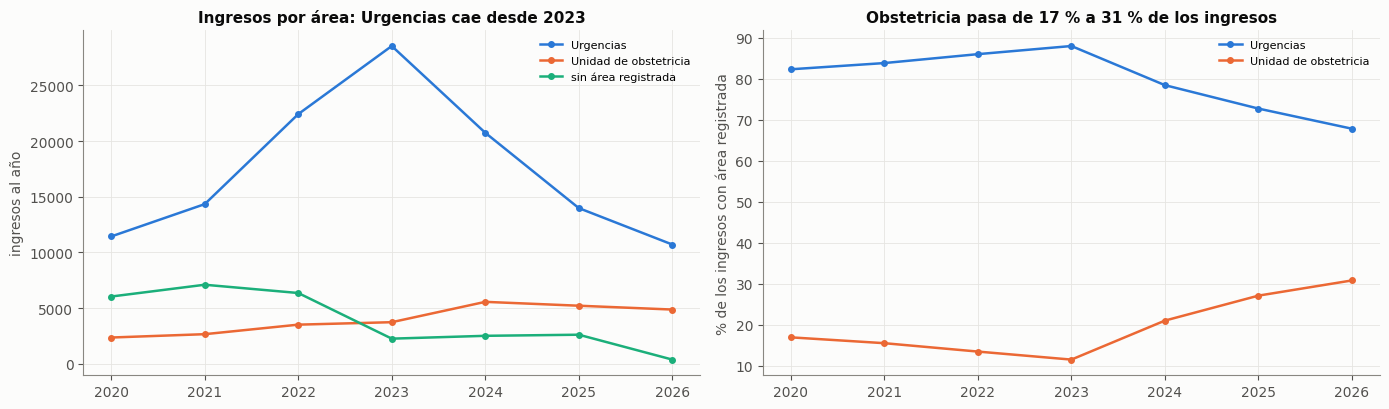

2026 va hasta septiembre (incompleto). Las áreas con pocos ingresos se suman en «otras áreas»; las casillas menores de 20 se ocultan.


,Urgencias,Unidad de obstetricia,sin área registrada,otras áreas
anio,,,,
2020,11.431,2.349,6.032,105
2021,14.336,2.649,7.092,113
2022,22.423,3.505,6.349,139
2023,28.544,3.726,2.247,164
2024,20.746,5.554,2.502,143
2025,13.979,5.207,2.601,32
2026,10.705,4.862,365,216


% de los ingresos con área registrada (sin contar «sin área»):


,Urgencias,Unidad de obstetricia,otras áreas
anio,,,
2020,"82,3","16,9","0,8"
2021,"83,8","15,5","0,7"
2022,"86,0","13,4","0,5"
2023,"88,0","11,5","0,5"
2024,"78,5","21,0","0,5"
2025,"72,7","27,1","0,2"
2026,"67,8","30,8","1,4"


área nueva de urgencias en 2026 (Urgencias 2 Sur): 131
ingresos 2020-2026, Urgencias: 122.164 | obstetricia: 27.852


In [5]:
# 2.1 Dónde se atiende (área de servicio del ingreso)
ar = area.groupby(["anio", "area"]).n.sum(min_count=1).unstack()
grandes = ["URGENCIAS", "UNIDAD OBSTETRICIA", "(sin area)"]
otras = ar.drop(columns=grandes).sum(axis=1, min_count=1)
tabla = pd.concat([ar[grandes], otras.rename("otras áreas")], axis=1).fillna(0)
tabla.columns = ["Urgencias", "Unidad de obstetricia", "sin área registrada", "otras áreas"]
con_area = tabla.drop(columns="sin área registrada")
cuota_a = 100 * con_area.div(con_area.sum(axis=1), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for i, c in enumerate(["Urgencias", "Unidad de obstetricia", "sin área registrada"]):
    axes[0].plot(tabla.index, tabla[c], marker="o", ms=4, color=CATEG[i], lw=1.8, label=c)
for i, c in enumerate(["Urgencias", "Unidad de obstetricia"]):
    axes[1].plot(cuota_a.index, cuota_a[c], marker="o", ms=4, color=CATEG[i], lw=1.8, label=c)
axes[0].set_ylabel("ingresos al año"); axes[0].set_title("Ingresos por área: Urgencias cae desde 2023"); axes[0].legend(fontsize=8)
axes[1].set_ylabel("% de los ingresos con área registrada"); axes[1].set_title("Obstetricia pasa de 17 % a 31 % de los ingresos"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("2026 va hasta septiembre (incompleto). Las áreas con pocos ingresos se suman en «otras áreas»; las casillas menores de", UMBRAL, "se ocultan.")
display(ocultar(tabla)); print("% de los ingresos con área registrada (sin contar «sin área»):"); display(cuota_a.style.format(lambda v: es(v, 1)))
print("área nueva de urgencias en 2026 (Urgencias 2 Sur):", int(ar.loc[2026, "URGENCIAS 2 SUR"]))
print("ingresos 2020-2026, Urgencias:", es(tabla["Urgencias"].sum(), 0), "| obstetricia:", es(tabla["Unidad de obstetricia"].sum(), 0))

## Lectura

**Dónde.** De 2020 a 2026 hay 122.164 ingresos en Urgencias y 27.852 en la unidad de obstetricia. Urgencias sube de 11.431 ingresos en 2020 a 28.544 en 2023 y baja a 20.746 en 2024, 13.979 en 2025 y 10.705 en 2026 hasta septiembre. En esos mismos años, el registro «sin área» pasa de 6.032 en 2020 a 7.092 en 2021, 2.247 en 2023 y 365 en 2026: la subida de Urgencias hasta 2023 es compatible con ingresos que antes no tenían área asignada, y por eso la mitad derecha del gráfico usa solo los ingresos con área.

**La obstetricia cambia de peso en 2024, no de forma sostenida.** Entre los ingresos con área registrada, su cuota fue de 16,9 % en 2020, bajó a 11,5 % en 2023, y subió a 21,0 % en 2024, 27,1 % en 2025 y 30,8 % en 2026. En conteos, de 3.726 ingresos en 2023 a 5.554 en 2024, cuando Urgencias bajaba. El momento coincide con el escalón de mayo de 2024 de la sección anterior: lo que se atiende es cada vez más embarazo y parto, que no depende del clima ni de las fiestas, y es un subconjunto que parece conservar su ingreso mientras caen los demás. Los datos no distinguen si el alza viene de la ciudad o de un cambio en la red de maternidades. En 2026 aparece además un área de urgencias nueva (131 ingresos), contada entre «otras áreas».



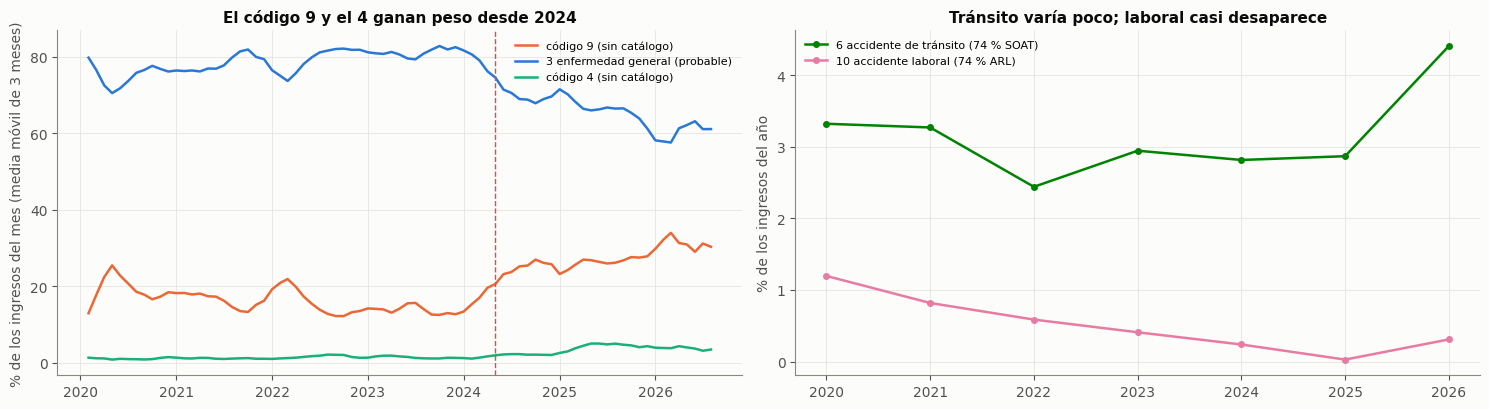

Ingresos por causa y año (casillas menores de 20 ocultas; «otros códigos» reúne los códigos 1, 2, 5, 7, 8 y 11):


causa,3 enfermedad general (probable),6 accidente de tránsito (74 % SOAT),10 accidente laboral (74 % ARL),código 9 (sin catálogo),código 4 (sin catálogo),otros códigos
anio,,,,,,
2020,15.201,661,238,3.531,221,55
2021,19.028,791,198,3.879,275,26
2022,25.720,791,190,5.137,516,61
2023,28.125,1.022,142,4.816,499,108
2024,21.477,815,69,6.076,515,<20
2025,14.534,626,<20,5.727,936,<20
2026,9.743,712,50,5.042,607,<20


% de los ingresos del año:


causa,3 enfermedad general (probable),6 accidente de tránsito (74 % SOAT),10 accidente laboral (74 % ARL),código 9 (sin catálogo),código 4 (sin catálogo),otros códigos
anio,,,,,,
2020,"76,4","3,3","1,2","17,7","1,1","0,3"
2021,"78,6","3,3","0,8","16,0","1,1","0,1"
2022,"79,3","2,4","0,6","15,8","1,6","0,2"
2023,"81,0","2,9","0,4","13,9","1,4","0,3"
2024,"74,2","2,8","0,2","21,0","1,8","0,0"
2025,"66,6","2,9","0,0","26,2","4,3","0,0"
2026,"60,3","4,4","0,3","31,2","3,8","0,0"


código 9, total 2020-2026: 34.208 | tránsito: 5.418
tránsito por día, 2022-2025: {2022: 2.2, 2023: 2.8, 2024: 2.2, 2025: 1.7}
código 9, % mensual (media móvil 3 m): {'2023-06-01': 15.5, '2024-01-01': 13.4, '2024-04-01': 19.6, '2024-06-01': 23.2, '2024-09-01': 25.4, '2025-06-01': 26.4, '2025-12-01': 27.8}


In [6]:
# 2.2 Por qué causa de ingreso (código de la base, sin diccionario)
rot = {"enfermedad general (probable)": "3 enfermedad general (probable)", "accidente de transito (74 % SOAT)": "6 accidente de tránsito (74 % SOAT)",
       "accidente laboral (74 % ARL)": "10 accidente laboral (74 % ARL)", "codigo 9 (sin catalogo)": "código 9 (sin catálogo)",
       "codigo 4 (sin catalogo)": "código 4 (sin catálogo)"}
ca = causa.groupby(["anio", "causa"]).n.sum(min_count=1).unstack()
raras = [c for c in ca.columns if c not in rot]
ca2 = ca[list(rot)].rename(columns=rot).copy(); ca2["otros códigos"] = ca[raras].sum(axis=1, min_count=1)
ca2 = ca2.fillna(0)
cu = 100 * ca2.div(ca2.sum(axis=1), axis=0)
cm = causa.groupby(["mes", "causa"]).n.sum(min_count=1).unstack().fillna(0)
cmp_ = 100 * cm.div(cm.sum(axis=1), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for i, c in enumerate(["codigo 9 (sin catalogo)", "enfermedad general (probable)", "codigo 4 (sin catalogo)"]):
    axes[0].plot(cmp_.index, cmp_[c].rolling(3, center=True).mean(), color=[NARANJA, AZUL, AQUA][i], lw=1.8, label=rot[c])
axes[0].set_ylabel("% de los ingresos del mes (media móvil de 3 meses)"); axes[0].set_title("El código 9 y el 4 ganan peso desde 2024")
axes[0].axvline(pd.Timestamp("2024-05-01"), color=ROJO, lw=1, ls="--"); axes[0].legend(fontsize=8)
for i, c in enumerate(["6 accidente de tránsito (74 % SOAT)", "10 accidente laboral (74 % ARL)"]):
    axes[1].plot(cu.index, cu[c], marker="o", ms=4, color=[VERDE, MAGENTA][i], lw=1.8, label=c)
axes[1].set_ylabel("% de los ingresos del año"); axes[1].set_title("Tránsito varía poco; laboral casi desaparece"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Ingresos por causa y año (casillas menores de", UMBRAL, "ocultas; «otros códigos» reúne los códigos 1, 2, 5, 7, 8 y 11):")
display(ocultar(ca2)); print("% de los ingresos del año:"); display(cu.style.format(lambda v: es(v, 1)))
print("código 9, total 2020-2026:", es(ca["codigo 9 (sin catalogo)"].sum(), 0), "| tránsito:", es(ca["accidente de transito (74 % SOAT)"].sum(), 0))
dias = pd.Series([365, 365, 366, 365], index=[2022, 2023, 2024, 2025])
print("tránsito por día, 2022-2025:", (ca["accidente de transito (74 % SOAT)"].loc[2022:2025] / dias).round(1).to_dict())
c9 = cmp_["codigo 9 (sin catalogo)"].rolling(3, center=True).mean()
print("código 9, % mensual (media móvil 3 m):", {k: round(c9.loc[k], 1) for k in ["2023-06-01", "2024-01-01", "2024-04-01", "2024-06-01", "2024-09-01", "2025-06-01", "2025-12-01"]})

## Lectura

**Por qué causa.** La enfermedad general (código 3, probable) es el grueso: 76,4 % de los ingresos en 2020, 81,0 % en 2023, 66,6 % en 2025 y 60,3 % en 2026. Cede el lugar al **código 9, sin catálogo**, que pasa de 13,9 % en 2023 a 21,0 % en 2024, 26,2 % en 2025 y 31,2 % en 2026, con 34.208 ingresos en total. En el gráfico mensual su peso (media móvil de tres meses) sube de 13,4 % en enero de 2024 a 19,6 % en abril, 23,2 % en junio y 27,8 % en diciembre de 2025: el ascenso arranca en los mismos meses del escalón del ingreso. El código 4 también gana peso (de 1,4 % en 2023 a 4,3 % en 2025). Sin diccionario no se puede decir qué son, y su crecimiento durante el cambio de régimen sugiere que la causa codificada refleja también quién entra a ingreso.

**Tránsito y laboral.** Los accidentes de tránsito suman 5.418 ingresos y son de 2,2 al día en 2022, 2,8 en 2023, 2,2 en 2024 y 1,7 en 2025: varían menos que el total de ingresos, que cae, y por eso su cuota sube a 4,4 % en 2026. Los accidentes laborales bajan de 238 ingresos en 2020 a 69 en 2024 y menos de 20 en 2025 (50 en 2026), un descenso de 1,2 % a 0,2 % de los ingresos que puede ser real o un cambio de codificación.

**Límite.** Solo los códigos 3, 6 y 10 tienen rótulo, y solo por inferencia. El 3 se llama «probable» porque se infiere de un cruce. Las áreas pequeñas se suman en «otras áreas» para no mostrar casillas con pocos casos.


---
# 3. Qué tienen: el diagnóstico principal

Se usa el diagnóstico principal CIE-10 del primer folio de cada ingreso que viene de un triage. En el periodo hay 178.365 ingresos, y 172.708 (96,8 %) tienen un diagnóstico visible tras la supresión de casillas pequeñas. Es el diagnóstico que pone el médico, no la nota de la enfermera. Solo describe al grupo que se ingresa, no a todos los que piden triage, y ese grupo cambió de composición en 2024 (sección 1).


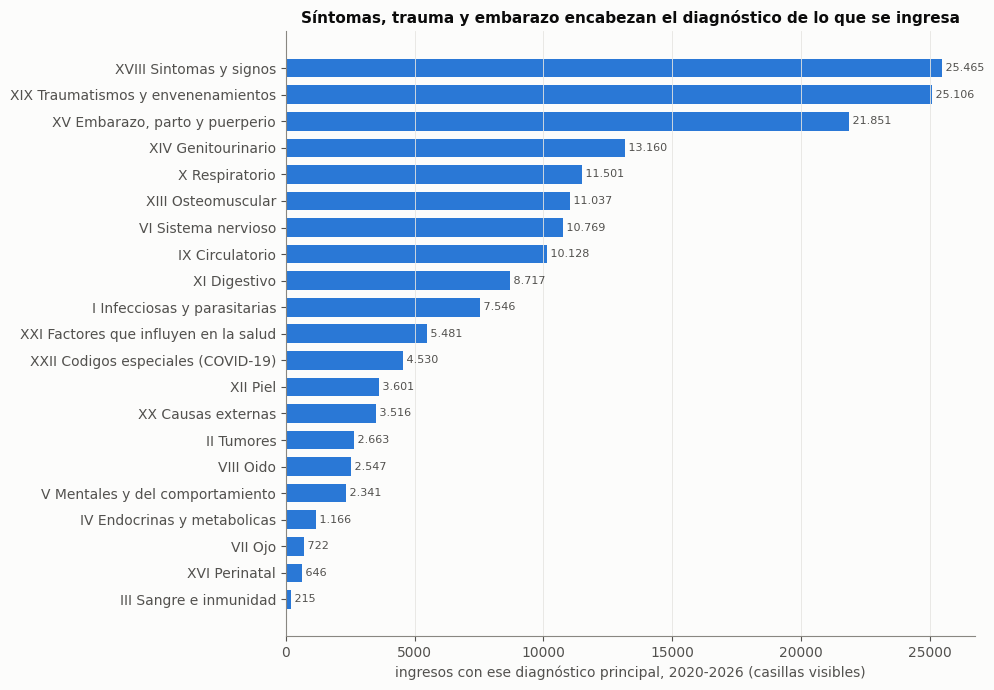

ingresos totales (con ingreso en el perfil de triage): 178.365
ingresos con diagnóstico visible: 172.708 | casillas semana × capítulo ocultas en origen: 20,6 %
cuota de los 5 mayores capítulos (%): {'XVIII Sintomas y signos': 14.7, 'XIX Traumatismos y envenenamientos': 14.5, 'XV Embarazo, parto y puerperio': 12.7, 'XIV Genitourinario': 7.6, 'X Respiratorio': 6.7}


código,subcódigo más usado,nombre del subcódigo,capítulo,ingresos 2020-2026
R10,R101,Dolor abdominal localizado en parte superior,XVIII Sintomas y signos,15.175
G44,G448,Otros sindromes de cefalea especificados,VI Sistema nervioso,5.281
A09,A09X,Diarrea y gastroenteritis de presunto origen infeccioso,I Infecciosas y parasitarias,4.944
M54,M545,Lumbago no especificado,XIII Osteomuscular,4.647
U07,U071,Covid-19 virus identificado,XXII Codigos especiales (COVID-19),4.577
N39,N390,"Infeccion de vias urinarias, sitio no especificado",XIV Genitourinario,4.537
R07,R072,Dolor precordial,XVIII Sintomas y signos,3.856
O62,O620,Contracciones primarias inadecuadas,"XV Embarazo, parto y puerperio",3.766
O47,O470,Falso trabajo de parto antes de la 37 semanas completas de gestacion,"XV Embarazo, parto y puerperio",3.248
G43,G439,"Migraña, no especificada",VI Sistema nervioso,2.572


Los códigos se muestran sumados en todo el periodo; la menor cifra de esta tabla es 2.012 ingresos.


In [7]:
# 3.1 Capítulos CIE-10 y códigos más frecuentes
cap = dxs.groupby("capitulo").n.sum().sort_values()
cap = cap[cap > 0]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(range(len(cap)), cap.values, color=AZUL, height=.7)
ax.set_yticks(range(len(cap)), cap.index)
for i, v in enumerate(cap.values): ax.text(v, i, " " + es(v, 0), va="center", fontsize=8, color=TINTA2)
ax.set_xlabel("ingresos con ese diagnóstico principal, 2020-2026 (casillas visibles)"); ax.set_title("Síntomas, trauma y embarazo encabezan el diagnóstico de lo que se ingresa")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()
print("ingresos totales (con ingreso en el perfil de triage):", es(a[1].sum(), 0))
tot_dx = dxs.n.sum(); print("ingresos con diagnóstico visible:", es(tot_dx, 0), "| casillas semana × capítulo ocultas en origen:", es(100 * dxs.suprimido.mean(), 1), "%")
print("cuota de los 5 mayores capítulos (%):", {k: round(v, 1) for k, v in (100 * cap.sort_values(ascending=False).head(5) / tot_dx).items()})
top = (dxc[~dxc.cod3.str.startswith("(otros")].groupby(["cod3", "subcodigo_mas_usado", "nombre", "capitulo"]).n.sum()
         .sort_values(ascending=False).head(15).reset_index())
top["nombre"] = top.nombre.str.strip().str.capitalize(); top["subcodigo_mas_usado"] = top.subcodigo_mas_usado.str.strip()
top.columns = ["código", "subcódigo más usado", "nombre del subcódigo", "capítulo", "ingresos 2020-2026"]
display(top.style.format({"ingresos 2020-2026": lambda v: es(v, 0)}).hide(axis="index"))
print("Los códigos se muestran sumados en todo el periodo; la menor cifra de esta tabla es", es(top.iloc[:, -1].min(), 0), "ingresos.")

## Lectura

**Lo que atiende el SES, según el médico.** Cinco capítulos reúnen el 56,2 % de los ingresos con diagnóstico visible: síntomas y signos (14,7 %), traumatismos y envenenamientos (14,5 %), embarazo, parto y puerperio (12,7 %), genitourinario (7,6 %) y respiratorio (6,7 %). Los códigos más frecuentes son el dolor abdominal localizado en la parte superior (R10, 15.175 ingresos), la cefalea (G44, 5.281; migraña G43, 2.572), la diarrea y gastroenteritis (A09, 4.944), el lumbago (M54, 4.647), la COVID-19 (U07, 4.577), la infección de vías urinarias (N39, 4.537), el dolor precordial (R07, 3.856) y, en obstetricia, las contracciones inadecuadas (O62, 3.766), el falso trabajo de parto (O47, 3.248) y la amenaza de aborto (O20, 2.012). En lo respiratorio dominan el EPOC con exacerbación (J44, 2.485) y el resfriado común (J00, 2.267). El trauma es el segundo capítulo pero está repartido en muchos códigos: el mayor, el traumatismo de cabeza (S09), tiene 2.185 ingresos. Son sobre todo golpes y contusiones, no el accidente de tránsito de la sección 2.

**Límite.** Los nombres corresponden a la subcategoría más usada por el hospital dentro de cada código de tres caracteres, porque el catálogo de la base no trae el nombre de la categoría.


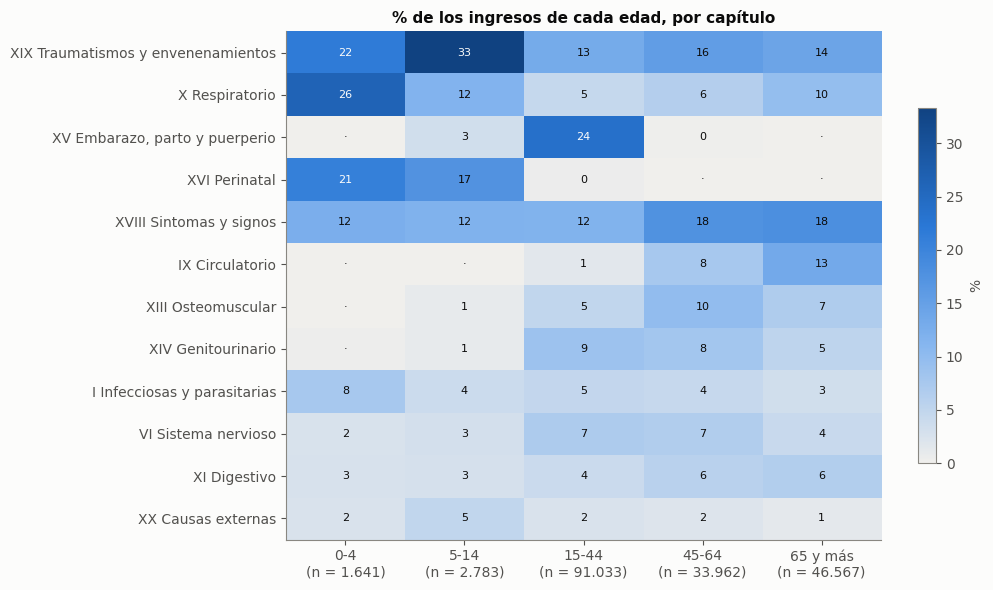

«·» marca una casilla con menos de 20 ingresos; no se rotula.
ingresos con diagnóstico y edad, por banda: {'0-4': 1641, '5-14': 2783, '15-44': 91033, '45-64': 33962, '65-+': 46567}
capítulo perinatal, ingresos por banda: {'0-4': 341, '15-44': 422, '45-64': 0, '5-14': 483, '65-+': 0} | % en 5-14: 38.8
cuota por banda (%), capítulos citados:


banda,0-4,5-14,15-44,45-64,65-+
capitulo,,,,,
X Respiratorio,26,12,5,6,10
XIX Traumatismos y envenenamientos,22,33,13,16,14
"XV Embarazo, parto y puerperio",0,3,24,0,0
XVI Perinatal,21,17,0,0,0
XVIII Sintomas y signos,12,12,12,18,18
IX Circulatorio,0,0,1,8,13


In [8]:
# 3.2 Qué capítulo pesa en cada edad
e = dxe.groupby(["capitulo", "banda"]).n.sum().unstack().fillna(0)
bandas = [b for b in ["0-4", "5-14", "15-44", "45-64", "65-+"] if b in e]
e = e[bandas]; cuota = 100 * e / e.sum()
sel = cuota.max(axis=1).sort_values(ascending=False).index[:12]
cuota_s, e_s = cuota.loc[sel], e.loc[sel]
etq = {"65-+": "65 y más"}
fig, ax = plt.subplots(figsize=(10.5, 6))
im = ax.imshow(cuota_s.values, cmap=SECUENCIAL, aspect="auto")
ax.set_xticks(range(len(bandas)), [etq.get(b, b) + "\n(n = " + es(e[b].sum(), 0) + ")" for b in bandas]); ax.set_yticks(range(len(sel)), sel)
for i in range(cuota_s.shape[0]):
    for j in range(cuota_s.shape[1]):
        v, n_ = cuota_s.iat[i, j], e_s.iat[i, j]
        ax.text(j, i, f"{v:.0f}" if n_ >= UMBRAL else "·", ha="center", va="center", fontsize=8, color=TINTA if v < 20 else SUP)
ax.grid(False); ax.set_title("% de los ingresos de cada edad, por capítulo"); fig.colorbar(im, ax=ax, shrink=.7, label="%")
plt.tight_layout(); plt.show()
print("«·» marca una casilla con menos de", UMBRAL, "ingresos; no se rotula.")
print("ingresos con diagnóstico y edad, por banda:", {b: int(e[b].sum()) for b in bandas})
pe = dxe[dxe.capitulo.eq("XVI Perinatal") & (dxe.banda != "sin edad")].groupby("banda").n.sum()
print("capítulo perinatal, ingresos por banda:", {k: int(v) for k, v in pe.items()}, "| % en 5-14:", round(100 * pe["5-14"] / pe.sum(), 1))
print("cuota por banda (%), capítulos citados:")
display(cuota.loc[["X Respiratorio", "XIX Traumatismos y envenenamientos", "XV Embarazo, parto y puerperio", "XVI Perinatal", "XVIII Sintomas y signos", "IX Circulatorio"]].style.format(lambda v: es(v, 0)))

## Lectura

**Por edad, el hospital es otro.** En los niños de 0 a 4 años pesan lo respiratorio (26 %), los traumatismos (22 %) y el capítulo perinatal (21 %). De 5 a 14 el 33 % es trauma. De 15 a 44, el embarazo es el 24 %. De 45 a 64 predominan los síntomas (18 %), el trauma (16 %), lo osteomuscular (10 %) y lo circulatorio (8 %). En los mayores de 65 años, síntomas (18 %), trauma (14 %), circulatorio (13 %) y respiratorio (10 %).

Esto fija a quién le importa cada factor del entorno, con la cautela de que son hipótesis que este cuaderno no contrasta: la literatura asocia el frío con la mortalidad cardiorrespiratoria (Kephart et al., 2022, 326 ciudades de América Latina, doi:10.1038/s41591-022-01872-6), lo que apunta a los mayores en lo respiratorio y lo circulatorio; lo respiratorio de los niños suele seguir a los virus; el trauma de 5 a 14 y de adultos jóvenes, con las actividades y el fin de semana; y el embarazo no depende del entorno. Las cifras de 0 a 4 años se apoyan en solo 1.641 ingresos con diagnóstico visible en siete años, y las de 5 a 14 en 2.783, frente a 91.033 de 15 a 44, 33.962 de 45 a 64 y 46.567 de 65 y más: los niños son pocos en este hospital.

**Una incoherencia que no se interpreta.** El capítulo perinatal tendría que concentrarse en los recién nacidos, y de sus 1.246 ingresos con edad visible, 341 están en la banda de 0 a 4, 483 en la de 5 a 14 (38,8 %) y 422 en la de 15 a 44. Una explicación posible es que la edad del triage no sea la del paciente ingresado cuando un ingreso agrupa a madre y recién nacido, pero los datos no lo muestran. La consecuencia práctica es que la banda de edad del triage, usada como subgrupo, puede no ser la edad del paciente en un grupo pequeño de ingresos.


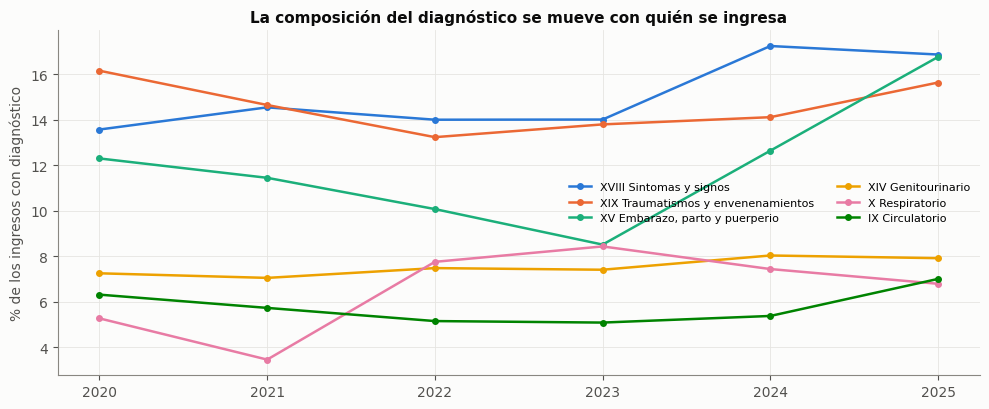

capitulo,XVIII Sintomas y signos,XIX Traumatismos y envenenamientos,"XV Embarazo, parto y puerperio",XIV Genitourinario,X Respiratorio,IX Circulatorio
anio,,,,,,
2020,"13,6","16,2","12,3","7,3","5,3","6,3"
2021,"14,5","14,7","11,4","7,0","3,5","5,7"
2022,"14,0","13,2","10,1","7,5","7,8","5,1"
2023,"14,0","13,8","8,5","7,4","8,4","5,1"
2024,"17,2","14,1","12,6","8,0","7,4","5,4"
2025,"16,9","15,6","16,8","7,9","6,8","7,0"


In [9]:
# 3.3 La composición del diagnóstico por año (cuota de cada capítulo entre los ingresos con diagnóstico)
d = dxs.assign(anio=dxs.semana.dt.year); d = d[d.anio.between(2020, 2025)]
c_ = d.groupby(["anio", "capitulo"]).n.sum().unstack().fillna(0)
cuo = 100 * c_.div(c_.sum(axis=1), axis=0)
cl = ["XVIII Sintomas y signos", "XIX Traumatismos y envenenamientos", "XV Embarazo, parto y puerperio", "XIV Genitourinario", "X Respiratorio", "IX Circulatorio"]
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, c in enumerate(cl): ax.plot(cuo.index, cuo[c], marker="o", ms=4, lw=1.8, color=CATEG[i], label=c)
ax.set_ylabel("% de los ingresos con diagnóstico"); ax.set_title("La composición del diagnóstico se mueve con quién se ingresa"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
display(cuo[cl].style.format(lambda v: es(v, 1)))

## Lectura

La composición del diagnóstico se mueve con el cambio de régimen de ingreso. La cuota de síntomas y signos sube de 13,6 % en 2020 a 17,2 % en 2024 y 16,9 % en 2025; la del embarazo baja de 12,3 % en 2020 a 8,5 % en 2023 y sube a 16,8 % en 2025; la de lo respiratorio es de 5,3 % en 2020, 3,5 % en 2021 (año de restricciones por la pandemia), 8,4 % en 2023 y 6,8 % en 2025; la de lo circulatorio, 6,3 % en 2020, 5,1 % en 2023 y 7,0 % en 2025. Un conteo de ingresos por capítulo hereda entonces los quiebres de la sección 1, y por eso en la sección 4 cada capítulo se mide como cuota de los ingresos del mes.


---
# 4. Cómo cambia lo que se ingresa a lo largo del año

Se compara el perfil mensual de los capítulos con un mecanismo externo conocido —respiratorio, infecciosas (sobre todo diarrea), traumatismos y embarazo— con el síntoma genérico como referencia. Cada capítulo se mide como su cuota de los ingresos con diagnóstico del mes, para que el cambio de régimen de ingreso no se confunda con una estación, y cada año se divide por su propia media, de modo que 1 significa un mes igual al promedio de su año. Se usa 2022-2025, para dejar fuera la pandemia y el año incompleto de 2026. La semana se asigna al mes en que empieza.


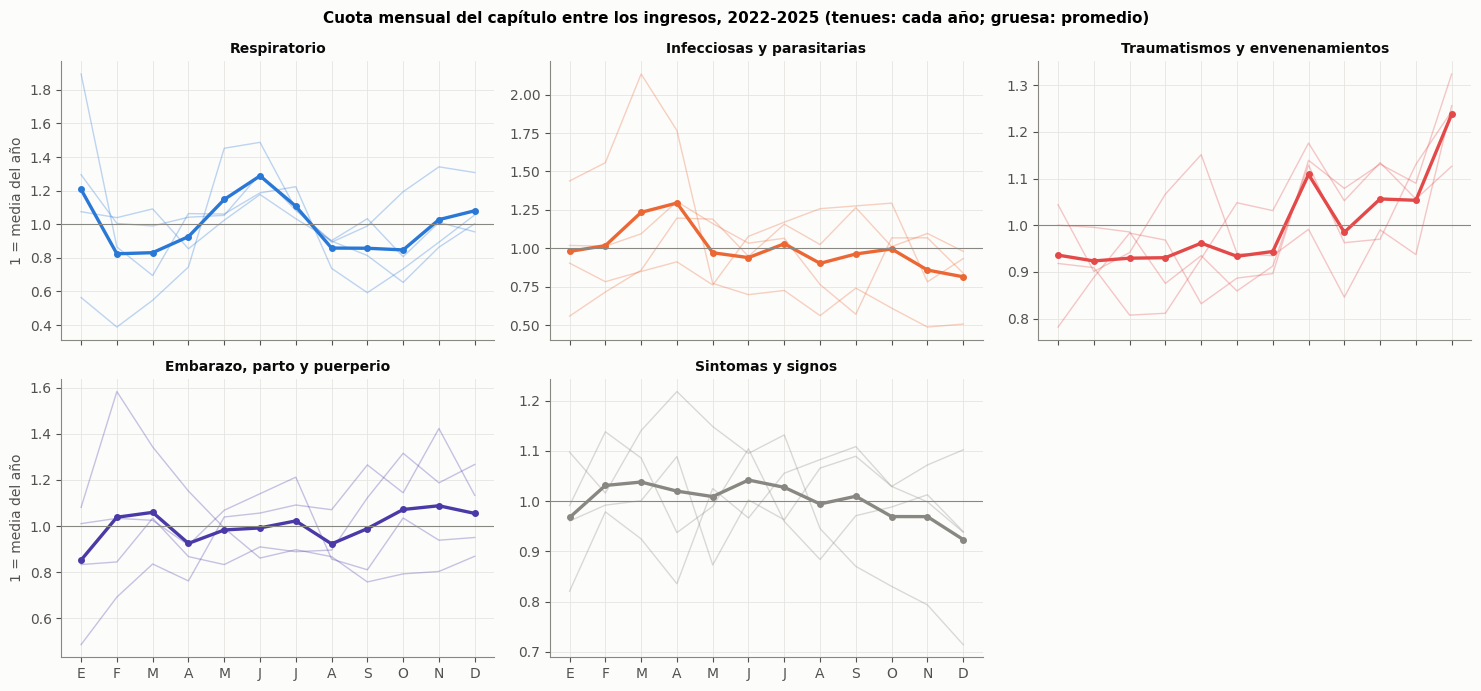

capítulo,mes pico,cuota ese mes (1 = media),años de 4 con ese mes sobre 1,mes valle,cuota ese mes,correlación de cada año con el promedio de los otros tres (2022 a 2025)
Respiratorio,jun,"1,29",4,feb,"0,82","-0,06, 0,39, 0,35, 0,60"
Infecciosas y parasitarias,abr,"1,29",3,dic,"0,81","-0,33, -0,47, -0,31, 0,25"
Traumatismos y envenenamientos,dic,"1,24",4,feb,"0,92","0,74, 0,27, 0,51, 0,74"
"Embarazo, parto y puerperio",nov,"1,09",2,ene,"0,85","-0,68, -0,20, -0,38, 0,04"
Sintomas y signos,jun,"1,04",3,dic,"0,92","-0,02, -0,23, -0,71, -0,51"


Respiratorio, cuota por mes y año:


m,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
a,,,,,,,,,,,,
2022,"0,56","0,39","0,55","0,75","1,45","1,49","1,09","0,89","0,99","1,19","1,34","1,31"
2023,"1,07","1,04","1,09","0,85","1,02","1,18","1,03","0,90","1,03","0,81","1,01","0,95"
2024,"1,89","0,86","0,69","1,06","1,06","1,19","1,22","0,74","0,59","0,73","0,89","1,06"
2025,"1,30","1,00","0,99","1,04","1,05","1,30","1,08","0,90","0,81","0,65","0,86","1,00"


Respiratorio, años (de 4) con la cuota sobre 1, por mes: {'ene': 3, 'feb': 2, 'mar': 1, 'abr': 2, 'may': 4, 'jun': 4, 'jul': 4, 'ago': 0, 'sep': 1, 'oct': 1, 'nov': 2, 'dic': 3}
Traumatismos, años (de 4) con la cuota sobre 1, por mes: {'ene': 2, 'feb': 0, 'mar': 0, 'abr': 1, 'may': 1, 'jun': 1, 'jul': 1, 'ago': 3, 'sep': 2, 'oct': 2, 'nov': 3, 'dic': 4}
Infecciosas, promedio en mar y abr: {3: 1.23, 4: 1.29} | años sobre 1 en mar y abr: [2, 3]
Respiratorio, promedio en may, jun y jul: {5: 1.15, 6: 1.29, 7: 1.11} | ene: 1.21


Traumatismos, promedio en dic y ago: {12: 1.24, 8: 1.11}


Respiratorio, conteo (1 = media del año): {'ene': 1.26, 'feb': 0.75, 'mar': 0.86, 'abr': 0.96, 'may': 1.19, 'jun': 1.36, 'jul': 1.16, 'ago': 0.84, 'sep': 0.83, 'oct': 0.86, 'nov': 0.9, 'dic': 1.04}
Traumatismos, conteo: {'ene': 0.97, 'feb': 0.85, 'mar': 0.97, 'abr': 0.96, 'may': 0.98, 'jun': 1.0, 'jul': 1.0, 'ago': 1.1, 'sep': 0.97, 'oct': 1.05, 'nov': 0.94, 'dic': 1.21}


In [10]:
# 4. Estacionalidad de lo que se ingresa: cuota mensual del capítulo, cada año contra su propia media
sel = {"X Respiratorio": AZUL, "I Infecciosas y parasitarias": NARANJA, "XIX Traumatismos y envenenamientos": ROJO,
       "XV Embarazo, parto y puerperio": VIOLETA, "XVIII Sintomas y signos": MUDO}
w = dxs[dxs.semana.between("2022-01-01", "2025-12-31")].copy()
w["mes"] = w.semana.dt.to_period("M").dt.to_timestamp()
total = w.groupby("mes").n.sum()
def curva(serie):
    d = pd.DataFrame({"v": serie}); d["a"], d["m"] = d.index.year, d.index.month
    d["r"] = d.v / d.groupby("a").v.transform("mean")
    return d.pivot(index="a", columns="m", values="r")
P = {c: curva(w[w.capitulo == c].groupby("mes").n.sum() / total) for c in sel}
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, (c, col) in zip(axes.ravel(), sel.items()):
    for a_ in P[c].index: ax.plot(range(1, 13), P[c].loc[a_], color=col, alpha=.3, lw=1)
    ax.plot(range(1, 13), P[c].mean(), color=col, lw=2.4, marker="o", ms=4)
    ax.axhline(1, color=MUDO, lw=.8); ax.set_title(c.split(" ", 1)[1], fontsize=10); ax.set_xticks(range(1, 13), [m_[0].upper() for m_ in MESES])
axes.ravel()[-1].axis("off"); axes[0, 0].set_ylabel("1 = media del año"); axes[1, 0].set_ylabel("1 = media del año")
fig.suptitle("Cuota mensual del capítulo entre los ingresos, 2022-2025 (tenues: cada año; gruesa: promedio)", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()
filas = []
for c in sel:
    p = P[c]; prom = p.mean()
    loo = [np.corrcoef(p.loc[a_], p.drop(a_).mean())[0, 1] for a_ in p.index]
    pico, valle = prom.idxmax(), prom.idxmin()
    filas.append({"capítulo": c.split(" ", 1)[1], "mes pico": MESES[pico - 1], "cuota ese mes (1 = media)": prom[pico], "años de 4 con ese mes sobre 1": int((p[pico] > 1).sum()),
                  "mes valle": MESES[valle - 1], "cuota ese mes": prom[valle], "correlación de cada año con el promedio de los otros tres (2022 a 2025)": ", ".join(es(x, 2) for x in loo)})
display(pd.DataFrame(filas).style.format({"cuota ese mes (1 = media)": lambda v: es(v, 2), "cuota ese mes": lambda v: es(v, 2)}).hide(axis="index"))
print("Respiratorio, cuota por mes y año:"); display(P["X Respiratorio"].rename(columns=dict(enumerate(MESES, 1))).style.format(lambda v: es(v, 2)))
print("Respiratorio, años (de 4) con la cuota sobre 1, por mes:", dict(zip(MESES, (P["X Respiratorio"] > 1).sum().tolist())))
print("Traumatismos, años (de 4) con la cuota sobre 1, por mes:", dict(zip(MESES, (P["XIX Traumatismos y envenenamientos"] > 1).sum().tolist())))
print("Infecciosas, promedio en mar y abr:", P["I Infecciosas y parasitarias"].mean().round(2)[[3, 4]].to_dict(), "| años sobre 1 en mar y abr:", (P["I Infecciosas y parasitarias"][[3, 4]] > 1).sum().tolist())
print("Respiratorio, promedio en may, jun y jul:", P["X Respiratorio"].mean().round(2)[[5, 6, 7]].to_dict(), "| ene:", round(P["X Respiratorio"].mean()[1], 2))
print("Traumatismos, promedio en dic y ago:", P["XIX Traumatismos y envenenamientos"].mean().round(2)[[12, 8]].to_dict())
# lo mismo con el conteo, para comparar con la cuota
Pc = {c: curva(w[w.capitulo == c].groupby("mes").n.sum()) for c in ["X Respiratorio", "XIX Traumatismos y envenenamientos"]}
print("Respiratorio, conteo (1 = media del año):", dict(zip(MESES, Pc["X Respiratorio"].mean().round(2))))
print("Traumatismos, conteo:", dict(zip(MESES, Pc["XIX Traumatismos y envenenamientos"].mean().round(2))))

## Lectura

**Solo dos patrones estacionales se repiten con claridad entre años: lo respiratorio a mitad de año y el trauma en diciembre.**

- **Respiratorio.** Su cuota supera la media de su año en mayo, junio y julio en los cuatro años (promedios de 1,15, 1,29 y 1,11); el pico es junio y el valle, febrero (0,82). Con el conteo en lugar de la cuota, el perfil es el mismo (junio 1,36, enero 1,26, febrero 0,75). Enero es menos confiable: su promedio es 1,21, pero el valor de 2022 es 0,56 y el de 2024, 1,89. Los primeros meses de 2022 tienen una cuota respiratoria muy baja (0,56, 0,39, 0,55 y 0,75 de enero a abril), un periodo en el que el diagnóstico de COVID-19 ocupa su propio capítulo y que puede distorsionar ese año. La correlación del perfil de cada año con el promedio de los otros tres es de -0,06 en 2022, 0,39, 0,35 y 0,60: el patrón se sostiene en tres de los cuatro años.
- **Traumatismos.** El pico es diciembre (1,24, por encima de 1 en los cuatro años) y agosto es el segundo (1,11, en tres años). Las correlaciones con los otros años son positivas en los cuatro (0,74, 0,27, 0,51, 0,74), el patrón más estable de la tabla. Es compatible con la temporada festiva, aunque el diagnóstico no identifica pólvora ni alcohol.

**Lo que antes se leía como diarrea en marzo y abril no es robusto.** El capítulo de infecciosas tiene su pico en abril (1,29; marzo, 1,23), pero superan 1 solo dos años en marzo y tres en abril, y las correlaciones con los demás años son negativas en tres de cuatro (-0,33, -0,47, -0,31, 0,25). El promedio de los cuatro años sugiere una estacionalidad que los años por separado no confirman. El embarazo (pico en noviembre, 1,09, en dos años de cuatro; correlaciones de -0,68, -0,20, -0,38 y 0,04) y el síntoma genérico (-0,02, -0,23, -0,71 y -0,51) no tienen perfil estacional estable, lo que corresponde a su papel de referencia.

**Estas series, con diagnóstico médico y sin leer una nota, son los desenlaces específicos disponibles desde 2020**: respiratorio, infecciosas, trauma y embarazo. Su valor es de descripción de subgrupo, no de predicción: en el barrido con los índices semanales de la ciudad (cuaderno 19), los ingresos respiratorios, infecciosos, digestivos y por trauma no mostraron ninguna asociación que sobreviviera a la corrección por comparaciones múltiples. El perfil estacional existe; lo que no se ha visto es que el clima semanal de la ciudad lo explique mejor que el mes del año.

**Límite.** Son cuatro años por mes, y el grupo cubre solo lo que se ingresa. Con tan pocas repeticiones, la concordancia entre años es la medida de confianza, no el tamaño del promedio. Que un patrón sea estacional no dice si lo causa el clima, el calendario escolar o la oferta del hospital.


---
# 5. Por qué se remite

Fuente: seguimiento de remisiones de 2023 a 2026. El motivo es un catálogo cerrado de 6 valores, que se comprueba en cada extracción. El motivo escrito a mano, que es texto clínico, no se consulta. Hay dos cifras de remisiones con distinta cobertura: la tabla por servicio oculta pocas casillas (6,8 %) y da el total más completo; la tabla por motivo oculta un tercio de sus casillas (33,3 %) porque se abre por mes, y por eso subestima.


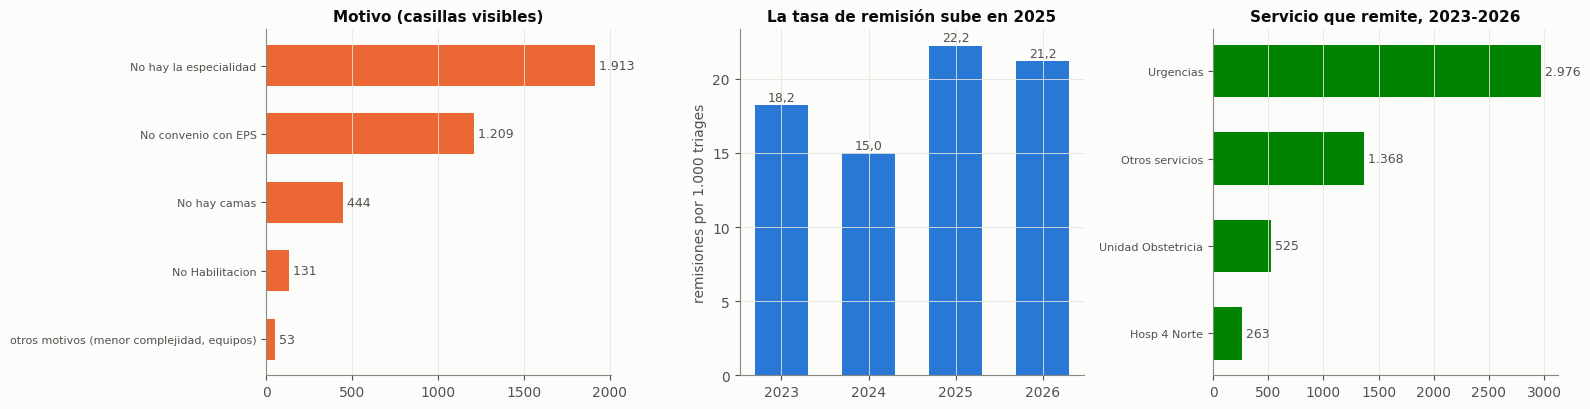

Remisiones por servicio (cifra más completa) y triages por año:


,remisiones,triages,por 1.000 triages
anio,,,
2023,1.280,70.215,"18,2"
2024,1.234,82.379,"15,0"
2025,1.619,72.838,"22,2"
2026,999,47.121,"21,2"


Remisiones con motivo visible por año (casillas menores de 20 ocultas; «<20» incluye las suprimidas en origen):


motivo,No disponibilidad de la especialidad,No convenio con EPS,No disponibilidad de camas,No Habilitacion,"otros motivos (menor complejidad, equipos)"
anio,,,,,
2023,575,331,110,<20,<20
2024,566,371,114,<20,<20
2025,487,360,156,21,29
2026,285,147,64,110,<20


remisiones con motivo visible: 3.750 de 5.132 ( 73,1 %) | Urgencias: 58,0 % de las remisiones por servicio
motivo, % de lo visible: {'No disponibilidad de la especialidad': 51.0, 'No convenio con EPS': 32.2, 'No disponibilidad de camas': 11.8, 'No Habilitacion': 3.5, 'otros motivos (menor complejidad, equipos)': 1.4}
tasa de «no hay convenio» por 1.000 triages (casillas visibles): {2023: 4.7, 2024: 4.5, 2025: 4.9, 2026: 3.1}
«No habilitación» visible en 2025 y 2026: {2025: 21.0, 2026: 110.0}


In [11]:
# 5. Cuántas remisiones, por qué motivo y desde dónde
trg = ib.groupby("anio").n.sum()
rem_anio = rs.groupby("anio").n.sum(min_count=1)
tasa_r = 1000 * rem_anio / trg.loc[rem_anio.index]
mot = rm.groupby(["anio", "motivo"]).n.sum(min_count=1).unstack()
mot["otros motivos (menor complejidad, equipos)"] = mot[["Menor complejidad", "No disponibilidad de equipos"]].sum(axis=1, min_count=1)
mot = mot.drop(columns=["Menor complejidad", "No disponibilidad de equipos"])
mot = mot[["No disponibilidad de la especialidad", "No convenio con EPS", "No disponibilidad de camas", "No Habilitacion", "otros motivos (menor complejidad, equipos)"]]
srv = rs.groupby("servicio").n.sum(min_count=1).sort_values(ascending=False)
srv.index = srv.index.str.strip().str.title()
srv_g = pd.concat([srv.head(3), pd.Series({"Otros servicios": srv.iloc[3:].sum()})])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
tm = mot.sum().sort_values()
axes[0].barh(range(len(tm)), tm.values, color=NARANJA, height=.6); axes[0].set_yticks(range(len(tm)), [t_.replace("No disponibilidad de", "No hay") for t_ in tm.index], fontsize=8)
for i, v in enumerate(tm.values): axes[0].text(v, i, " " + es(v, 0), va="center", fontsize=9, color=TINTA2)
axes[0].set_title("Motivo (casillas visibles)"); axes[0].grid(axis="y", visible=False)
axes[1].bar(tasa_r.index, tasa_r.values, color=AZUL, width=.6)
for x, v in tasa_r.items(): axes[1].text(x, v + .3, es(v, 1), ha="center", fontsize=9, color=TINTA2)
axes[1].set_ylabel("remisiones por 1.000 triages"); axes[1].set_title("La tasa de remisión sube en 2025"); axes[1].set_xticks(tasa_r.index)
sv = srv_g.sort_values()
axes[2].barh(range(len(sv)), sv.values, color=VERDE, height=.6); axes[2].set_yticks(range(len(sv)), sv.index, fontsize=8)
for i, v in enumerate(sv.values): axes[2].text(v, i, " " + es(v, 0), va="center", fontsize=9, color=TINTA2)
axes[2].set_title("Servicio que remite, 2023-2026"); axes[2].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("Remisiones por servicio (cifra más completa) y triages por año:")
display(pd.DataFrame({"remisiones": rem_anio, "triages": trg.loc[rem_anio.index], "por 1.000 triages": tasa_r}).style.format({"remisiones": lambda v: es(v, 0), "triages": lambda v: es(v, 0), "por 1.000 triages": lambda v: es(v, 1)}))
print("Remisiones con motivo visible por año (casillas menores de", UMBRAL, "ocultas; «<" + str(UMBRAL) + "» incluye las suprimidas en origen):"); display(ocultar(mot))
tv, tt = rm.n.sum(), rem_anio.sum()
print("remisiones con motivo visible:", es(tv, 0), "de", es(tt, 0), "(", es(100 * tv / tt, 1), "%) | Urgencias:", es(100 * srv.iloc[0] / srv.sum(), 1), "% de las remisiones por servicio")
print("motivo, % de lo visible:", {k: round(v, 1) for k, v in (100 * mot.sum() / mot.sum().sum()).items()})
print("tasa de «no hay convenio» por 1.000 triages (casillas visibles):", {int(k): round(1000 * mot["No convenio con EPS"].loc[k] / trg.loc[k], 1) for k in [2023, 2024, 2025, 2026]})
print("«No habilitación» visible en 2025 y 2026:", mot["No Habilitacion"].loc[[2025, 2026]].to_dict())

## Lectura

**Cuántas.** Las remisiones por servicio suman 1.280 en 2023, 1.234 en 2024, 1.619 en 2025 y 999 en 2026 hasta septiembre. Por cada 1.000 triages, son 18,2, 15,0, 22,2 y 21,2: la tasa de remisión sube en 2025, aunque los triages totales bajaron. Urgencias origina el 58,0 % de las remisiones (2.976 de 5.132), seguida de obstetricia (525).

**Por qué.** De las 5.132 remisiones solo 3.750 (73,1 %) tienen su motivo visible; lo que sigue es un piso, no un total. Entre ellas, la ausencia de la especialidad pesa el 51,0 % (1.913), la ausencia de convenio con la EPS el 32,2 % (1.209), la ausencia de camas el 11,8 % (444), la no habilitación el 3,5 % (131) y los demás motivos (menor complejidad, ausencia de equipos) el 1,4 % (53). Coincide con la descripción institucional: sin especialista se estabiliza y se remite, y se remite a donde la EPS tiene convenio.

**El convenio no sube con la crisis de Nueva EPS.** Las remisiones visibles por ausencia de convenio son 4,7, 4,5 y 4,9 por 1.000 triages en 2023, 2024 y 2025, y 3,1 en 2026 (331, 371, 360 y 147 remisiones). La tasa no aumenta cuando Nueva EPS se desploma. Con una cobertura del 73 % y casillas mensuales ocultas, esto no excluye un efecto, pero tampoco lo muestra.

**La «no habilitación» aparece de golpe.** Tiene menos de 20 remisiones visibles en 2023 y 2024, 21 en 2025 y 110 en 2026. Algún servicio dejó de estar habilitado, un cambio institucional que modifica qué puede atender el hospital; estos agregados no dicen cuál.

**Límite.** Son las remisiones que registra este sistema, desde 2023. El destino no se consulta.


---
# 6. Conclusiones y límites

**Qué hospital es.** El SES es una puerta de urgencias general: recibe todo, estabiliza y decide. Decide ingresar a menos gente que antes: de 49,5 % de los triages en 2023 a 30,0 % en 2025, en escalones de mayo de 2024 (nivel IV) y de septiembre de 2024 a enero de 2025 (nivel III), que no se explican por un cambio de mezcla de niveles ni por la crisis de Nueva EPS, posterior. Los grupos que dejaron de ingresar son los adultos y los mayores; en los niños el ingreso subió. Lo que se queda es cada vez más obstetricia (de 11,5 % de los ingresos con área registrada en 2023 a 30,8 % en 2026). Lo que se remite lo explican la ausencia de especialidad (51,0 % de las remisiones con motivo visible) y de convenio con la EPS (32,2 %).

**Qué significa para la pregunta del proyecto.**

1. El conteo total de triages mide la puerta, y la mueven la red y las decisiones del hospital, además del calendario. Un cambio de nivel de ingreso como el de 2024 altera qué parte del triage es «del hospital» sin que haya cambiado nada en el entorno. Un modelo del conteo total necesita esa información como estado explícito.
2. Las series por diagnóstico solo describen lo que se ingresa, y heredan los quiebres de la sección 1: deben medirse como cuota de los ingresos, nunca como conteo.
3. Los mecanismos del entorno se ven en lo que se atiende, en su época y en su subgrupo: lo respiratorio, en mayo a julio, en los cuatro años estudiados, y el trauma, en diciembre. La diarrea en marzo y abril no se sostiene año por año. Los candidatos naturales para los subgrupos son los mayores (frío, circulatorio y respiratorio) y los niños (virus), los segundos con pocos ingresos para sostener un análisis fino.
4. Hasta aquí no se ha encontrado que los índices semanales de la ciudad expliquen estos ingresos (cuaderno 19). La descripción del hospital delimita quién podría verse afectado, pero no es una prueba de que lo esté.

**Límites del análisis.**

- Las casillas con menos de 5 casos están ocultas en origen (entre el 6,7 % y el 36,1 % según la tabla), y en las tablas mostradas se ocultan además las menores de 20. Las sumas son algo menores que el total real, y la tabla de motivos de remisión recoge solo el 73,1 % de las remisiones.
- Solo se describe a quien ingresa. A quien se orienta fuera no se le conoce el diagnóstico.
- Los códigos de causa de ingreso no tienen diccionario; el 9 y el 4 crecen y no se sabe qué son.
- La banda de edad viene del triage y no es coherente con el capítulo perinatal en una parte de los casos.
- El nivel de triage se redefinió en 2024-2025, y sus tasas de ingreso de un periodo completo mezclan regímenes.
- La estacionalidad se apoya en cuatro años por mes y en semanas asignadas al mes en que empiezan; 2026 solo llega a septiembre.
- Estos agregados no distinguen si el escalón de mayo de 2024 fue de política, de registro o de la población que llega.
